# Perfiles diarios de PM2.5 en Pekín

Estudiamos las mediciones horarias de 2010 a 2014 para descubrir qué perfiles diarios de PM2.5 se repiten, en qué meses son más frecuentes los días del grupo de concentración alta y qué condiciones meteorológicas acompañan a cada grupo.

## Preprocesamiento

Usamos la fecha y hora local de Pekín para ordenar la serie y aplicamos las decisiones de limpieza documentadas en el EDA y en la primera entrega.

In [2]:
from pathlib import Path

import pandas as pd

ruta = Path("data") / "dataset.csv"
datos = pd.read_csv(ruta, na_values=["NA"])

componentes = ["year", "month", "day", "hour"]
datos["fecha_hora"] = (
    pd.to_datetime(datos[componentes], errors="raise")
    .dt.tz_localize("Asia/Shanghai")
)

datos = datos.sort_values("fecha_hora").reset_index(drop=True)

display(datos[["fecha_hora", "pm2.5", "TEMP", "cbwd"]].head())

,fecha_hora,pm2.5,TEMP,cbwd
0,2010-01-01 00:00:00+08:00,NaN,-11.0,NW
1,2010-01-01 01:00:00+08:00,NaN,-12.0,NW
2,2010-01-01 02:00:00+08:00,NaN,-11.0,NW
3,2010-01-01 03:00:00+08:00,NaN,-14.0,NW
4,2010-01-01 04:00:00+08:00,NaN,-12.0,NW


Comprobamos la coherencia entre temperatura y el punto de rocío. DEWP debe ser menor o igual que la temperatura de aire TEMP. 

In [3]:
rocio_superior = datos["DEWP"] > datos["TEMP"]

discrepancias = datos.loc[
    rocio_superior, ["fecha_hora", "TEMP", "DEWP"]
].copy()
discrepancias["diferencia_C"] = discrepancias["DEWP"] - discrepancias["TEMP"]

print(f"Registros con DEWP superior a TEMP: {len(discrepancias)}")
display(discrepancias)

Registros con DEWP superior a TEMP: 1


,fecha_hora,TEMP,DEWP,diferencia_C
6727,2010-10-08 07:00:00+08:00,12.0,13,1.0


La comprobación detectó un único registro en el que el punto de rocío supera en 1 °C a la temperatura del aire.

Siguiendo la decisión de la primera entrega, mantenemos TEMP y ajustamos DEWP a 12 °C, el cambio mínimo que satisface la regla manteniendo fija la temperatura.

In [4]:
datos_limpios = datos.copy()

fecha_ajuste = pd.Timestamp("2010-10-08 07:00", tz="Asia/Shanghai")
fila_ajuste = (
    datos_limpios["fecha_hora"].eq(fecha_ajuste)
    & datos_limpios["DEWP"].gt(datos_limpios["TEMP"])
)

datos_limpios["DEWP_original"] = datos_limpios["DEWP"]
datos_limpios["DEWP_corregido"] = fila_ajuste
datos_limpios.loc[fila_ajuste, "DEWP"] = datos_limpios.loc[fila_ajuste, "TEMP"]

display(datos_limpios.loc[fila_ajuste, ["fecha_hora", "DEWP_original", "DEWP", "TEMP"]])

,fecha_hora,DEWP_original,DEWP,TEMP
6727,2010-10-08 07:00:00+08:00,13,12,12.0


### Tabla horaria para el análisis

Empezamos el 2 de enero de 2010 a las 00:00, cuando aparece la primera medición de PM2.5. Las ausencias posteriores se conservan como `NaN` para mantener la secuencia horaria. `datos_analisis` reúne 43.800 horas, de las que 2.043 carecen de lectura de PM2.5.

In [5]:
datos_analisis = (
    datos_limpios.iloc[24:]
    .drop(columns=["No", "DEWP_original", "DEWP_corregido"])
    .reset_index(drop=True)
)

datos_analisis.head()

,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,fecha_hora
0,2010,1,2,0,129.0,-16,-4.0,1020.0,SE,1.79,0,0,2010-01-02 00:00:00+08:00
1,2010,1,2,1,148.0,-15,-4.0,1020.0,SE,2.68,0,0,2010-01-02 01:00:00+08:00
2,2010,1,2,2,159.0,-11,-5.0,1021.0,SE,3.57,0,0,2010-01-02 02:00:00+08:00
3,2010,1,2,3,181.0,-7,-5.0,1022.0,SE,5.36,1,0,2010-01-02 03:00:00+08:00
4,2010,1,2,4,138.0,-7,-5.0,1022.0,SE,6.25,2,0,2010-01-02 04:00:00+08:00


## ¿Qué perfiles diarios de PM2.5 se repiten en Pekín?

PAA convierte cada día en seis medias de cuatro horas, y k-means agrupa los días cuyos seis valores se parecen.

### Representación de los días con PAA

Construimos una fila por día con una columna para cada hora. Seleccionamos los días con 24 lecturas para que todas las franjas se calculen con la misma cobertura.

In [6]:
pm25_por_dia = (
    datos_analisis.assign(dia=datos_analisis["fecha_hora"].dt.date)
    .pivot(index="dia", columns="hour", values="pm2.5")
    .reindex(columns=range(24))
)

dias_completos = pm25_por_dia.dropna()

perfiles_paa = pd.DataFrame({
    f"{inicio:02d}–{inicio + 3:02d}": (
        dias_completos.loc[:, inicio:inicio + 3].mean(axis=1)
    )
    for inicio in range(0, 24, 4)
})

display(perfiles_paa.head())
print(perfiles_paa.shape)

,00–03,04–07,08–11,12–15,16–19,20–23
dia,,,,,,
2010-01-02,154.25,119.00,136.00,156.00,160.50,150.00
2010-01-03,68.25,81.25,86.00,97.00,67.50,73.00
2010-01-04,47.00,25.75,26.25,29.50,28.50,31.00
2010-01-05,29.00,27.50,30.50,35.00,56.25,76.50
2010-01-06,56.75,25.25,31.25,40.25,69.75,115.25


(1571, 6)


La tabla tiene **1.571 días y seis franjas**. Los 254 días incompletos quedan fuera del agrupamiento, así cada media resume cuatro lecturas observadas. El siguiente gráfico compara las lecturas horarias de un día con su representación PAA.

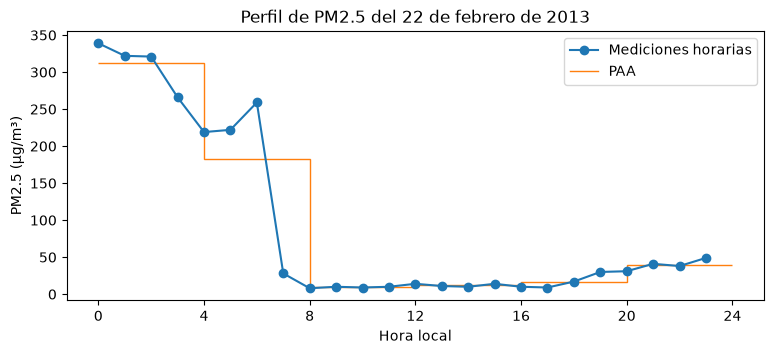

In [7]:
import matplotlib.pyplot as plt

dia = pd.Timestamp("2013-02-22").date()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(
    range(24), dias_completos.loc[dia],
    marker="o", label="Mediciones horarias",
)
ax.stairs(
    perfiles_paa.loc[dia], edges=range(0, 25, 4),
    baseline=None, label="PAA",
)
ax.set(
    title="Perfil de PM2.5 del 22 de febrero de 2013",
    xlabel="Hora local",
    ylabel="PM2.5 (µg/m³)",
    xticks=range(0, 25, 4),
)
ax.legend()
plt.show()

El 22 de febrero de 2013, la media pasó de **312 µg/m³** en la franja de 00:00 a 03:59 a **9,25 µg/m³** en la de 08:00 a 11:59. PAA conserva esa caída y suaviza las variaciones dentro de cada franja.

### Agrupamiento con k-means

Probamos entre dos y seis grupos. La puntuación *silhouette* mide cuánto se parecen los días dentro de su grupo en relación con su proximidad a los demás grupos. Usamos la mayor puntuación para elegir `k`. Cada línea del gráfico representa las seis medias de un grupo.

,silhouette
k,
2,0.517
3,0.425
4,0.423
5,0.333
6,0.334


,días
grupo,
0,1190
1,381


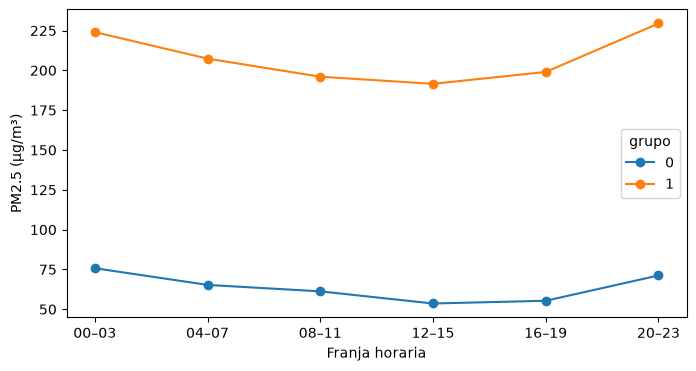

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

modelos = {}
resultados = []

for k in range(2, 7):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=42)
    grupos = modelo.fit_predict(perfiles_paa)

    modelos[k] = modelo
    resultados.append({
        "k": k,
        "silhouette": silhouette_score(perfiles_paa, grupos),
    })

evaluacion = pd.DataFrame(resultados).set_index("k")
display(evaluacion.round(3))

k_elegido = evaluacion["silhouette"].idxmax()
dias_agrupados = perfiles_paa.assign(grupo=modelos[k_elegido].labels_)
perfil_medio = dias_agrupados.groupby("grupo").mean()

display(dias_agrupados.groupby("grupo").size().to_frame("días"))

ax = perfil_medio.T.plot(marker="o", figsize=(8, 4))
ax.set(xlabel="Franja horaria", ylabel="PM2.5 (µg/m³)")
plt.show()

La puntuación más alta fue **0,517 con dos grupos**. El grupo 0 reúne **1.190 días** de concentración más baja y el grupo 1 reúne **381 días** de concentración más alta, un 24,3 % de los días agrupados. En ambos perfiles el PM2.5 desciende hasta la franja de 12:00 a 15:59 y vuelve a subir por la noche. La principal diferencia entre los dos grupos es su nivel de concentración a lo largo del día.

### ¿En qué meses aparece más el grupo de PM2.5 alto?

Para cada mes dividimos los días asignados al grupo alto entre los días agrupados de ese mes. La columna `cobertura_pct` indica qué proporción del calendario mensual está representada en el agrupamiento.

,dias_analizados,dias_grupo_alto,dias_totales,pct_grupo_alto,cobertura_pct
mes,,,,,
1,135,39,154,28.9,87.7
2,135,45,141,33.3,95.7
3,130,35,155,26.9,83.9
4,121,22,150,18.2,80.7
5,137,15,155,10.9,88.4
6,122,31,150,25.4,81.3
7,138,33,155,23.9,89.0
8,118,12,155,10.2,76.1
9,128,23,150,18.0,85.3


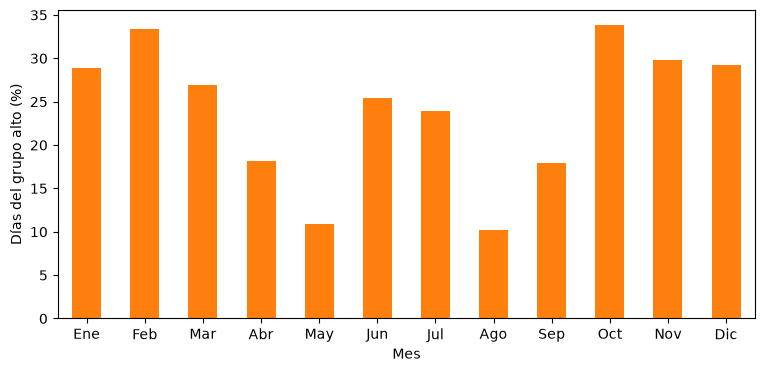

In [9]:
grupo_alto = perfil_medio.mean(axis=1).idxmax()

por_mes = (
    dias_agrupados.assign(
        mes=pd.to_datetime(dias_agrupados.index).month,
        es_alto=dias_agrupados["grupo"].eq(grupo_alto),
    )
    .groupby("mes")
    .agg(
        dias_analizados=("grupo", "size"),
        dias_grupo_alto=("es_alto", "sum"),
    )
)

por_mes["dias_totales"] = pd.to_datetime(pm25_por_dia.index).month.value_counts()
por_mes["pct_grupo_alto"] = (
    100 * por_mes["dias_grupo_alto"] / por_mes["dias_analizados"]
)
por_mes["cobertura_pct"] = (
    100 * por_mes["dias_analizados"] / por_mes["dias_totales"]
)

display(por_mes.round(1))

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

ax = por_mes["pct_grupo_alto"].plot.bar(
    color="tab:orange", figsize=(9, 4), rot=0
)
ax.set_xticks(range(12), meses)
ax.set(xlabel="Mes", ylabel="Días del grupo alto (%)")
plt.show()

Entre los días agrupados, el perfil alto es más frecuente en **octubre (33,8 %)** y **febrero (33,3 %)**, y menos frecuente en **agosto (10,2 %)** y **mayo (10,9 %)**. La cobertura también varía por mes. En agosto se pudo agrupar el 76,1 % de los días y en febrero el 95,7 %. Estas proporciones describen el conjunto de días completos disponible en cada mes.

### ¿Qué direcciones de viento aparecen en cada grupo?

Asociamos cada registro meteorológico horario con el grupo asignado a su día. Contamos las categorías de `cbwd` y calculamos su porcentaje sobre el total de horas de cada grupo. De este modo recogemos los cambios de dirección que se producen dentro de un mismo día.

In [10]:
horas_agrupadas = (
    datos_analisis.assign(dia=datos_analisis["fecha_hora"].dt.date)
    .join(dias_agrupados[["grupo"]], on="dia", how="inner")
)

horas_agrupadas["nivel_grupo"] = (
    horas_agrupadas["grupo"].eq(grupo_alto)
    .map({True: "Alto", False: "Bajo"})
)

por_viento = pd.crosstab(
    horas_agrupadas["nivel_grupo"],
    horas_agrupadas["cbwd"],
    normalize="index",
).mul(100)

display(por_viento.round(1))

cbwd,NE,NW,SE,cv
nivel_grupo,,,,
Alto,10.1,21.2,39.8,28.8
Bajo,11.8,36.3,32.7,19.2


El viento del noroeste (`NW`) aparece en el **36,3 %** de las horas del grupo bajo y en el **21,2 %** de las del alto. El viento del sureste (`SE`) es más frecuente en el grupo alto, con un 39,8 % frente al 32,7 % del grupo bajo. Como el viento también varía a lo largo del año, repetimos la comparación del noroeste dentro de cada mes.

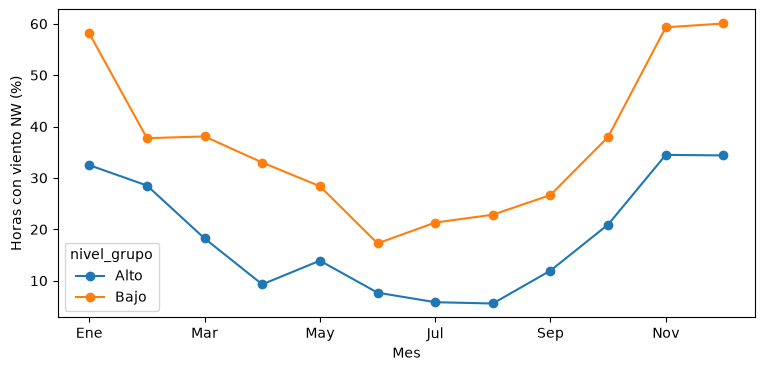

In [11]:
nw_por_mes = (
    horas_agrupadas.assign(es_nw=horas_agrupadas["cbwd"].eq("NW"))
    .groupby(["month", "nivel_grupo"])["es_nw"]
    .mean()
    .unstack()
    .mul(100)
)

ax = nw_por_mes.rename(index=dict(enumerate(meses, start=1))).plot(
    marker="o", figsize=(9, 4)
)
ax.set(xlabel="Mes", ylabel="Horas con viento NW (%)")
plt.show()

La proporción de viento del noroeste es mayor en el grupo bajo en **los doce meses**. En enero, por ejemplo, representa el **58,1 %** de sus horas frente al **32,5 %** en el grupo alto. La asociación se mantiene al comparar el mismo mes del calendario. Los grupos se definieron con el PM2.5 y el viento se incorpora después para interpretarlos.

### ¿Cómo se comparan las demás variables meteorológicas?

Calculamos la temperatura, el punto de rocío y la presión medios de cada día, y la mediana diaria del viento acumulado (`Iws`). Para describir un día típico de cada grupo, comparamos las medianas de esos resúmenes diarios.

In [12]:
meteo_diaria = (
    datos_analisis.assign(dia=datos_analisis["fecha_hora"].dt.date)
    .groupby("dia")
    .agg(
        temp_media=("TEMP", "mean"),
        rocio_medio=("DEWP", "mean"),
        presion_media=("PRES", "mean"),
        iws_mediana=("Iws", "median"),
    )
    .join(dias_agrupados[["grupo"]], how="inner")
)

meteo_diaria["nivel_grupo"] = (
    meteo_diaria["grupo"].eq(grupo_alto).map({True: "Alto", False: "Bajo"})
)
meteo_diaria["mes"] = pd.to_datetime(meteo_diaria.index).month

variables_meteo = ["temp_media", "rocio_medio", "presion_media", "iws_mediana"]

display(meteo_diaria.groupby("nivel_grupo")[variables_meteo].median().round(2))

,temp_media,rocio_medio,presion_media,iws_mediana
nivel_grupo,,,,
Alto,8.58,1.75,1016.88,3.12
Bajo,14.79,1.10,1016.02,6.26


Al juntar todos los meses, la mediana de la temperatura media diaria es de **8,6 °C** en el grupo alto y **14,8 °C** en el bajo. Los grupos tienen distinta composición a lo largo del año, así que calculamos de nuevo las medianas dentro de cada mes. En la tabla siguiente, cada diferencia se calcula restando el valor del grupo bajo al del grupo alto.

In [13]:
por_mes_y_grupo = (
    meteo_diaria.groupby(["mes", "nivel_grupo"])[variables_meteo].median()
)

diferencias = (
    por_mes_y_grupo.xs("Alto", level="nivel_grupo")
    - por_mes_y_grupo.xs("Bajo", level="nivel_grupo")
)

display(diferencias.round(2))

,temp_media,rocio_medio,presion_media,iws_mediana
mes,,,,
1,1.42,9.92,-3.48,-9.73
2,3.29,8.31,-3.67,-4.48
3,0.92,8.75,-9.04,-6.92
4,1.23,7.71,-2.02,-1.00
5,1.19,6.48,3.13,-3.25
6,0.79,2.83,-2.54,1.34
7,-0.04,3.21,1.08,4.03
8,0.54,3.04,0.73,1.00
9,0.67,2.33,-3.25,-0.67


Dentro del mismo mes, el grupo alto tiene una temperatura típica mayor en **10 de los 12 meses**. En febrero la diferencia es de **+3,3 °C**. El punto de rocío es mayor en el grupo alto en **los doce meses**, mientras que las diferencias de presión y viento acumulado cambian de signo según el mes. La comparación mensual permite separar parte del patrón de calendario al describir estas asociaciones.

## ¿Qué aporta la meteorología al estimar el PM2.5?

Comparamos dos regresiones lineales sobre las horas con PM2.5 observado. La primera usa la hora del día y el mes. La segunda añade la dirección del viento, el viento acumulado, la temperatura, el punto de rocío y la presión medidos en la misma hora.

Ajustamos ambos modelos con 2010–2013 y los evaluamos sobre las mismas 8.661 horas de 2014. El error absoluto medio (MAE) expresa en µg/m³ cuánto se aleja, en promedio, la estimación de la concentración observada.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

observadas = datos_analisis.loc[datos_analisis["pm2.5"].notna()]
entreno = observadas.loc[observadas["year"] < 2014]
prueba = observadas.loc[observadas["year"] == 2014]

configuraciones = {
    "Calendario": (["hour", "month"], []),
    "Calendario + meteorología": (
        ["hour", "month", "cbwd"],
        ["TEMP", "DEWP", "PRES", "Iws"],
    ),
}

resultados_regresion = []

for nombre, (categoricas, numericas) in configuraciones.items():
    columnas = categoricas + numericas
    codificador = ColumnTransformer([
        ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore"), categoricas),
        ("numericas", "passthrough", numericas),
    ])

    modelo = make_pipeline(codificador, LinearRegression())
    modelo.fit(entreno[columnas], entreno["pm2.5"])

    predicciones = modelo.predict(prueba[columnas]).clip(min=0)
    resultados_regresion.append({
        "modelo": nombre,
        "MAE": mean_absolute_error(prueba["pm2.5"], predicciones),
    })

display(pd.DataFrame(resultados_regresion).set_index("modelo").round(2))

,MAE
modelo,
Calendario,68.06
Calendario + meteorología,51.41


Al añadir meteorología, el MAE baja de **68,06 a 51,41 µg/m³**, una reducción del **24,5 %** respecto al modelo de calendario. La meteorología medida en la misma hora ayuda a estimar la concentración. Para interpretar el error medio, conviene comprobar por separado cómo se comporta el modelo en las horas con PM2.5 alto.

### ¿Cómo se comporta la regresión cuando el PM2.5 es alto?

Evaluamos el modelo con meteorología por separado en las horas con PM2.5 alto y en el resto de horas de 2014. Definimos el umbral con el percentil 95 del periodo de entrenamiento (2010–2013), que es de **282 µg/m³**. Un error medio negativo indica que la concentración estimada queda por debajo de la observada.

In [15]:
umbral_pm25 = entreno["pm2.5"].quantile(0.95)

errores = prueba[["pm2.5"]].copy()
errores["estimado"] = predicciones
errores["error"] = errores["estimado"] - errores["pm2.5"]
errores["error_absoluto"] = errores["error"].abs()
errores["nivel_observado"] = errores["pm2.5"].ge(umbral_pm25).map({
    True: "PM2.5 alto",
    False: "Resto de horas",
})

diagnostico = errores.groupby("nivel_observado").agg(
    horas=("pm2.5", "size"),
    observado_medio=("pm2.5", "mean"),
    estimado_medio=("estimado", "mean"),
    MAE=("error_absoluto", "mean"),
    error_medio=("error", "mean"),
)

display(diagnostico.round(2))

,horas,observado_medio,estimado_medio,MAE,error_medio
nivel_observado,,,,,
PM2.5 alto,516,366.33,170.21,196.12,-196.12
Resto de horas,8145,80.72,95.29,42.24,14.58


En las **516 horas de PM2.5 alto**, la concentración fue de **366,33 µg/m³** de media y el modelo estimó **170,21 µg/m³**. El MAE fue de **196,12 µg/m³** en esas horas y de **42,24 µg/m³** en el resto. La mejora en el MAE global al añadir meteorología convive con una subestimación importante de las concentraciones altas.

## Pronóstico de PM2.5 a una hora

Ahora queremos anticipar la concentración de la hora siguiente a partir del historial disponible en cada momento. Conservamos la cuadrícula horaria y los huecos de PM2.5. Usamos 2010–2013 para el diagnóstico y la selección del modelo, y reservamos 2014 para la evaluación final.

### Evolución del nivel mensual

Dibujamos la mediana de cada mes con al menos un 75 % de cobertura. La línea suavizada promedia las medianas de una ventana de 12 meses y exige al menos diez meses con mediana disponible. El resumen mensual sirve para visualizar cambios de nivel. El pronóstico se ajusta sobre la serie horaria.

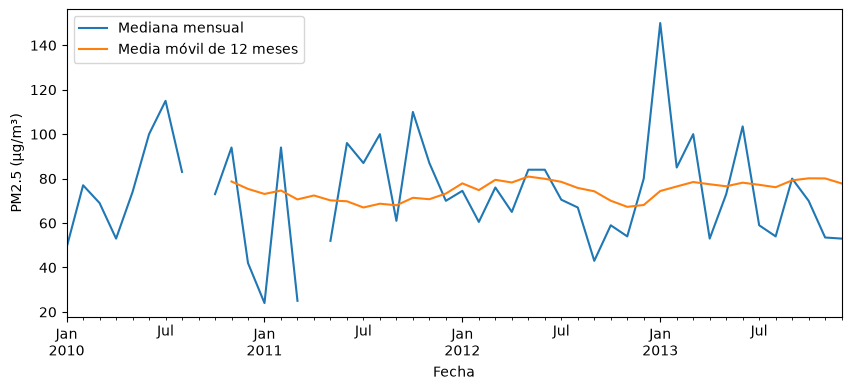

In [16]:
serie_horaria = datos_analisis.set_index("fecha_hora").asfreq("h")
corte = pd.Timestamp("2014-01-01", tz=serie_horaria.index.tz)

pm_entreno = serie_horaria.loc[serie_horaria.index < corte, "pm2.5"]
pm_prueba = serie_horaria.loc[serie_horaria.index >= corte, "pm2.5"]

resumen_arima = pm_entreno.resample("MS").agg(
    mediana="median",
    horas_observadas="count",
    horas_totales="size",
)
resumen_arima["cobertura"] = (
    resumen_arima["horas_observadas"] / resumen_arima["horas_totales"]
)

mediana_mensual = resumen_arima["mediana"].where(
    resumen_arima["cobertura"] >= 0.75
)
suavizado_anual = mediana_mensual.rolling(12, min_periods=10).mean()

ax = pd.DataFrame({
    "Mediana mensual": mediana_mensual,
    "Media móvil de 12 meses": suavizado_anual,
}).plot(figsize=(10, 4))

ax.set(xlabel="Fecha", ylabel="PM2.5 (µg/m³)")
plt.show()

La línea suavizada baja de unos **75 µg/m³** al cierre de 2010 a **68** al cierre de 2012, y vuelve a subir hasta **78** al cierre de 2013. La mediana mensual presenta cambios más bruscos, como el valor de **150 µg/m³** en enero de 2013. La trayectoria suavizada sugiere cambios de nivel en ambos sentidos.

### Autocorrelación y diferencia horaria

Aplicamos `log1p` para comprimir los valores altos y conservar los ceros. Comparamos el logaritmo del PM2.5 con su diferencia horaria. La ACF mide cuánto se relacionan dos valores separados por un retardo. La PACF mide esa relación descontando la influencia de los retardos intermedios. Calculamos la ACF sobre la cuadrícula de entrenamiento con sus huecos y la PACF sobre el tramo continuo más largo, de **1.330 horas**.

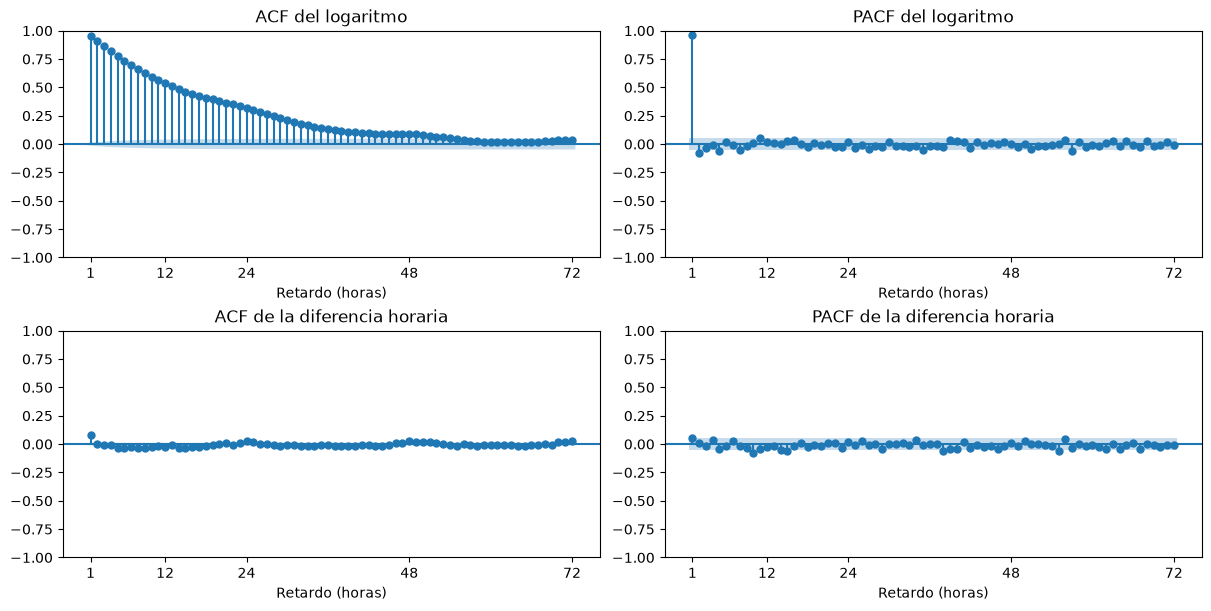

In [17]:
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

pm_log = np.log1p(pm_entreno)

observado = pm_log.notna()
tramos = observado.ne(observado.shift()).cumsum()
tramo_mayor = tramos[observado].value_counts().idxmax()
log_continuo = pm_log.loc[tramos.eq(tramo_mayor)]

fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")

plot_acf(pm_log, lags=72, missing="conservative", zero=False,
         ax=axes[0, 0], title="ACF del logaritmo")
plot_pacf(log_continuo, lags=72, method="ywm", zero=False,
          ax=axes[0, 1], title="PACF del logaritmo")

plot_acf(pm_log.diff(), lags=72, missing="conservative", zero=False,
         ax=axes[1, 0], title="ACF de la diferencia horaria")
plot_pacf(log_continuo.diff().iloc[1:], lags=72, method="ywm", zero=False,
          ax=axes[1, 1], title="PACF de la diferencia horaria")

for ax in axes.flat:
    ax.set(xlabel="Retardo (horas)", xticks=[1, 12, 24, 48, 72])

plt.show()

En niveles logarítmicos, la ACF empieza alrededor de **0,96** y cae gradualmente, mientras que en la PACF domina el retardo de una hora. Eso orienta la prueba de AR(1) y AR(2). Tras diferenciar, la ACF del primer retardo baja a **0,08** y la mayoría de los demás valores se acercan a cero. Probamos por ello un ARIMA(0,1,1) sobre el logaritmo. Los retardos de 24, 48 y 72 horas presentan picos poco marcados, así que para estos candidatos mantenemos la diferenciación estacional en cero.

### Selección del modelo en 2013

Ajustamos los candidatos con 2010–2012 y comparamos su MAE en las mismas **8.678 horas observadas de 2013**. La referencia de persistencia pronostica la próxima hora repitiendo la última lectura disponible. En cada evaluación usamos las observaciones anteriores a la hora pronosticada y expresamos el error en la escala original de µg/m³.

In [18]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

inicio_validacion = pd.Timestamp("2013-01-01", tz=pm_entreno.index.tz)
pm_ajuste = pm_entreno.loc[pm_entreno.index < inicio_validacion]
pm_validacion = pm_entreno.loc[pm_entreno.index >= inicio_validacion]

log_ajuste = np.log1p(pm_ajuste)
log_validacion = np.log1p(pm_validacion)

pronosticos_validacion = pd.DataFrame({
    "Persistencia": pm_entreno.ffill().shift(1).reindex(pm_validacion.index)
})

for orden in [(1, 0, 0), (2, 0, 0), (0, 1, 1)]:
    constante = "c" if orden[1] == 0 else "n"
    ajuste = SARIMAX(log_ajuste, order=orden, trend=constante).fit(disp=False)

    resultado = ajuste.extend(log_validacion)
    pred_log = resultado.get_prediction(information_set="predicted").predicted_mean
    pronosticos_validacion[f"ARIMA{orden}"] = np.expm1(pred_log).clip(lower=0)

validas = pm_validacion.notna()
mae_validacion = (
    pronosticos_validacion.loc[validas]
    .sub(pm_validacion.loc[validas], axis=0)
    .abs()
    .mean()
    .sort_values()
)

display(mae_validacion.round(2).to_frame("MAE (µg/m³)"))

,MAE (µg/m³)
"ARIMA(0, 1, 1)",13.04
Persistencia,13.21
"ARIMA(2, 0, 0)",13.91
"ARIMA(1, 0, 0)",14.03


**ARIMA(0,1,1)** obtiene el menor MAE en 2013, **13,04 µg/m³**, frente a **13,21 µg/m³** de persistencia, **13,91 µg/m³** de AR(2) y **14,03 µg/m³** de AR(1). La mejora respecto a la referencia es de alrededor del **1,3 %**. Este es el orden que se selecciona para reajustar con 2010–2013 y comprobar el pronóstico en 2014.

### Evaluación final en 2014

Reajustamos el ARIMA(0,1,1) seleccionado en la validación con todos los datos de 2010–2013. En 2014 hacemos pronósticos a una hora: cada método usa las observaciones disponibles hasta la hora anterior. Evaluamos los dos métodos sobre las mismas horas con PM2.5 medido, en la escala original de µg/m³.

Además del MAE global, calculamos el error en las horas de concentración alta. El umbral es el percentil 95 del PM2.5 observado en 2010–2013.

In [19]:
arima_final = SARIMAX(
    np.log1p(pm_entreno),
    order=(0, 1, 1),
    trend="n",
).fit(disp=False)

resultado_2014 = arima_final.extend(np.log1p(pm_prueba))
pred_log_2014 = resultado_2014.get_prediction(
    information_set="predicted"
).predicted_mean

pronosticos_2014 = pd.DataFrame({
    "Persistencia": (
        serie_horaria["pm2.5"].ffill().shift(1).reindex(pm_prueba.index)
    ),
    "ARIMA(0,1,1)": np.expm1(pred_log_2014).clip(lower=0),
})

errores_2014 = pronosticos_2014.sub(pm_prueba, axis=0).abs()
umbral_alto_2014 = pm_entreno.quantile(0.95)

comparacion_final = pd.DataFrame({
    "MAE global": errores_2014.loc[pm_prueba.notna()].mean(),
    "MAE en PM2.5 alto": errores_2014.loc[pm_prueba.ge(umbral_alto_2014)].mean(),
})

display(comparacion_final.round(2))

,MAE global,MAE en PM2.5 alto
Persistencia,11.96,25.00
"ARIMA(0,1,1)",11.78,24.65


En las **8.661 horas observadas de 2014**, ARIMA obtuvo un MAE de **11,78 µg/m³**, frente a **11,96 µg/m³** de persistencia. La reducción del error fue de aproximadamente **1,5 %**. En las **516 horas** con una concentración de al menos **282 µg/m³**, el MAE pasó de **25,00** a **24,65 µg/m³**.

La mejora fue pequeña en ambos casos. La fuerte dependencia entre lecturas consecutivas hace que repetir la última medición sea una referencia competitiva para pronosticar a una hora.